### Using PyTrends Search Engine Data

In [2]:
pip install nltk


[notice] A new release of pip is available: 24.0 -> 26.2.2
[notice] To update, run: pip3.12 install --upgrade pip
Note: you may need to restart the kernel to use updated packages.


In [3]:
pip install pytrends


[notice] A new release of pip is available: 24.0 -> 26.2.2
[notice] To update, run: pip3.12 install --upgrade pip
Note: you may need to restart the kernel to use updated packages.


In [4]:
# Load libraries
import matplotlib.pyplot as plt
import nltk
import pandas as pd
import plotly.graph_objects as go
import re
import time
import pytrends

from nltk.corpus import stopwords
from nltk.stem import WordNetLemmatizer
from pytrends.request import TrendReq
from sklearn.decomposition import TruncatedSVD
from sklearn.feature_extraction.text import CountVectorizer, TfidfVectorizer
from sklearn.metrics.pairwise import cosine_similarity

# Download 'punkt' resource
nltk.download('punkt')
nltk.download('punkt_tab')

[nltk_data] Downloading package punkt to /Users/pujadas/nltk_data...
[nltk_data]   Package punkt is already up-to-date!
[nltk_data] Downloading package punkt_tab to
[nltk_data]     /Users/pujadas/nltk_data...
[nltk_data]   Package punkt_tab is already up-to-date!


True

/Library/Frameworks/Python.framework/Versions/3.12/lib/python3.12/site-packages/pytrends/request.py:260: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  df = df.fillna(False)


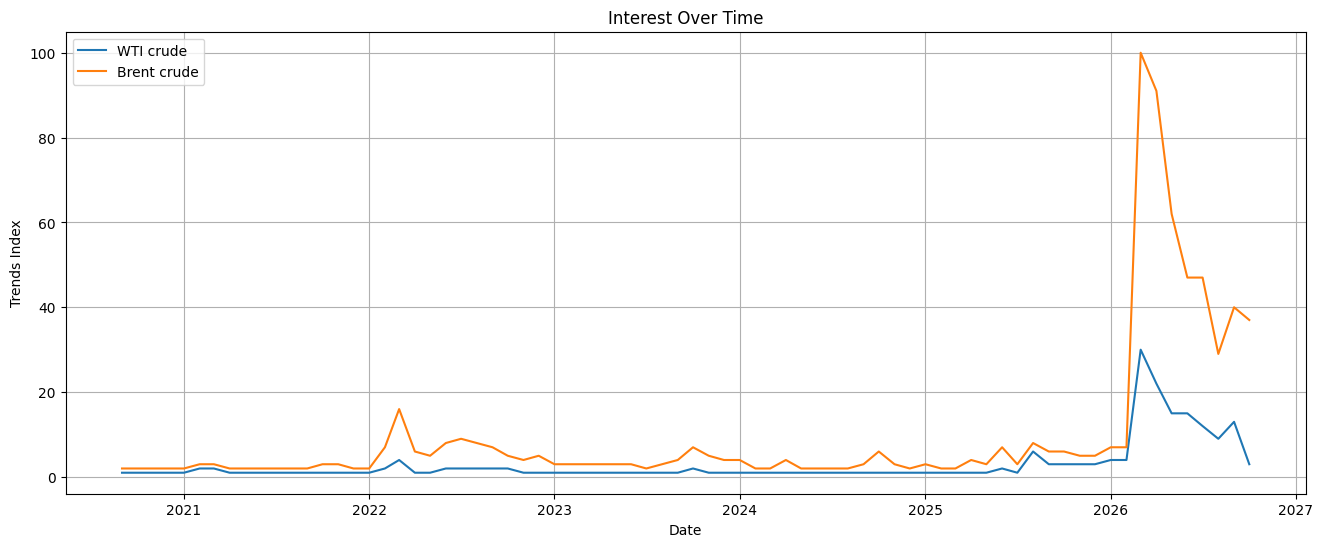

In [5]:
# Initialize an instance of the TrendReq class with US region and 360 timezone
pytrends = TrendReq(hl='en-US', tz=360)

# Define the list of keywords and timeframe
kw_list = ["WTI crude", "Brent crude"]
timeframe = '2020-09-01 2026-10-01' 

# Build the payload and get the interest over time data
pytrends.build_payload(kw_list, timeframe=timeframe)
interest_over_time_df = pytrends.interest_over_time()

# Create a figure and axes and plot the data
plt.figure(figsize=(16, 6))
for term in kw_list:
  plt.plot(interest_over_time_df.index, interest_over_time_df[term], label=term)

plt.xlabel('Date')
plt.ylabel('Trends Index')
plt.title('Interest Over Time')
plt.legend(loc='upper left')
plt.grid(True)
plt.show()

In [6]:
# Initialize an instance of the TrendReq class and build the payload
pytrends = TrendReq(hl='en-US', tz=360)
pytrends.build_payload(["Brent crude"], timeframe='2026-01-01 2026-10-01')

# Get the interest by region data
interest_by_region_df = pytrends.interest_by_region()
interest_by_region_df.sort_values(by="Brent crude", ascending=False).head(10)

,Brent crude
geoName,
South Africa,100
New Zealand,59
India,56
Singapore,53
Ireland,48
United Kingdom,43
United Arab Emirates,38
Pakistan,30
South Korea,25


In [7]:
# Initialize an instance of the TrendReq class and build the payload
pytrends = TrendReq(hl='en-US', tz=360)
pytrends.build_payload(["Brent crude"], timeframe='2026-01-01 2026-10-01')

# Wait for 10 seconds before making the next request to avoid overloading the server
time.sleep(10)

# Get the related queries
related_queries_dict = pytrends.related_queries()

# Print the top related queries
print("Top related queries:")
print(related_queries_dict["Brent crude"]["top"])

# Print the rising related queries
print("\nRising related queries:")
print(related_queries_dict["Brent crude"]["rising"])

Top related queries:
                         query  value
0            brent crude price    100
1              crude oil price     59
2              brent oil price     55
3  brent crude oil price today     14
4       brent crude oil prices      7

Rising related queries:
                         query  value
0       brent crude oil prices     60
1  brent crude oil price today     40
